# Project Summary

The objective of this project is to analyze employee performance at INX Future Inc. and identify important factors associated with performance ratings.

The dataset contains 1,200 employee records and 28 columns. Data exploration, preprocessing, visualization, and machine learning were performed using Python, Pandas, Matplotlib, Seaborn, and Scikit-learn.

Six baseline classification models and two tuned models were evaluated. The Tuned Decision Tree achieved the best overall results among the evaluated models, with 93.75% test accuracy, a Macro F1-score of 0.8996, and a Macro Recall of 0.8661.

Feature importance analysis identified Employee Environment Satisfaction, Employee Last Salary Hike Percentage, and Years Since Last Promotion as the three most important features in the selected model. These findings can help HR explore employee satisfaction, salary growth, and career development when planning performance improvement initiatives.

# INX Future Inc. — Employee Performance Analysis

## 1. Project Overview
The objective of this project is to analyze employee performance at INX Future Inc. and identify the factors associated with employee performance ratings. We will also build a Machine Learning model to predict employee performance ratings.

## 2. Project Objectives
- Analyze employee data and understand its structure.
- Perform Exploratory Data Analysis (EDA) to identify patterns and trends.
- Compare employee performance across different departments.
- Identify the top 3 factors associated with employee performance.
- Build and evaluate Machine Learning classification models to predict `PerformanceRating`.
- Provide data-driven recommendations to improve employee performance.

## 3. Project Workflow

**Step 1: Problem Understanding**  
Understand the business problem, project objectives, and target variable.

**Step 2: Data Loading and Inspection**  
Load the dataset and examine its rows, columns, data types, and structure.

**Step 3: Data Cleaning**  
Check for missing values, duplicate records, and data quality issues.

**Step 4: Exploratory Data Analysis (EDA)**  
Analyze employee performance by department and explore relationships between performance ratings and factors such as job satisfaction, environment satisfaction, work-life balance, salary hike, and training.

**Step 5: Data Preprocessing and Feature Engineering**  
Separate features and target, encode categorical variables, and prepare the data for Machine Learning.

**Step 6: Train-Test Split**  
Divide the dataset into training and testing sets to evaluate model performance on unseen data.

**Step 7: Model Building**  
Train suitable classification algorithms to predict employee performance ratings.

**Step 8: Model Evaluation**  
Compare models using appropriate evaluation metrics such as accuracy, precision, recall, F1-score, and confusion matrix.

**Step 9: Feature Importance Analysis**  
Identify the most influential features using suitable model-based techniques.

**Step 10: Business Insights and Recommendations**  
Summarize the findings and suggest practical actions that may help improve employee performance.

**Step 11: Final Conclusion and Project Documentation**  
Present the final results, key insights, model performance, limitations, and recommendations.

## 4. Target Variable
`PerformanceRating`

This is the variable we aim to predict using Machine Learning classification models.

## 5. Expected Outcome
A completed Employee Performance Analysis project containing exploratory analysis, department-wise insights, evaluated prediction models, important performance-related factors, and actionable business recommendations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
%pip install xlrd>=2.0.1

Note: you may need to restart the kernel to use updated packages.


In [3]:
df = pd.read_excel("INX_Future_Inc_Employee_Performance_CDS_Project2_Data_V1.8.xls")
print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully
Dataset shape: (1200, 28)


,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,...,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,...,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,...,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,...,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,...,4,10,1,3,2,2,2,2,No,3


In [4]:
# 1.dataset dimension
print("rows and columns:", df.shape)


rows and columns: (1200, 28)


In [5]:
# 2.All column names
print("\ncolumn names:")
for col in df.columns:
    print(col)


column names:
EmpNumber
Age
Gender
EducationBackground
MaritalStatus
EmpDepartment
EmpJobRole
BusinessTravelFrequency
DistanceFromHome
EmpEducationLevel
EmpEnvironmentSatisfaction
EmpHourlyRate
EmpJobInvolvement
EmpJobLevel
EmpJobSatisfaction
NumCompaniesWorked
OverTime
EmpLastSalaryHikePercent
EmpRelationshipSatisfaction
TotalWorkExperienceInYears
TrainingTimesLastYear
EmpWorkLifeBalance
ExperienceYearsAtThisCompany
ExperienceYearsInCurrentRole
YearsSinceLastPromotion
YearsWithCurrManager
Attrition
PerformanceRating


In [6]:
# 3.Data types and non-null values
print("Dataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   EmpNumber                     1200 non-null   object
 1   Age                           1200 non-null   int64 
 2   Gender                        1200 non-null   object
 3   EducationBackground           1200 non-null   object
 4   MaritalStatus                 1200 non-null   object
 5   EmpDepartment                 1200 non-null   object
 6   EmpJobRole                    1200 non-null   object
 7   BusinessTravelFrequency       1200 non-null   object
 8   DistanceFromHome              1200 non-null   int64 
 9   EmpEducationLevel             1200 non-null   int64 
 10  EmpEnvironmentSatisfaction    1200 non-null   int64 
 11  EmpHourlyRate                 1200 non-null   int64 
 12  EmpJobInvolvement             1200 non-null   int64 
 1

In [7]:
# 4.Missing values
print("\nMissing values:")
df.isnull().sum()


Missing values:


EmpNumber                       0
Age                             0
Gender                          0
EducationBackground             0
MaritalStatus                   0
EmpDepartment                   0
EmpJobRole                      0
BusinessTravelFrequency         0
DistanceFromHome                0
EmpEducationLevel               0
EmpEnvironmentSatisfaction      0
EmpHourlyRate                   0
EmpJobInvolvement               0
EmpJobLevel                     0
EmpJobSatisfaction              0
NumCompaniesWorked              0
OverTime                        0
EmpLastSalaryHikePercent        0
EmpRelationshipSatisfaction     0
TotalWorkExperienceInYears      0
TrainingTimesLastYear           0
EmpWorkLifeBalance              0
ExperienceYearsAtThisCompany    0
ExperienceYearsInCurrentRole    0
YearsSinceLastPromotion         0
YearsWithCurrManager            0
Attrition                       0
PerformanceRating               0
dtype: int64

In [8]:
# 5.Duplicate Records
print("\nduplicate rows:",df.duplicated().sum())



duplicate rows: 0


### 1. Employee Count by Department

This graph shows the number of employees in each department at INX Future Inc. It helps us understand the distribution of employees across departments.

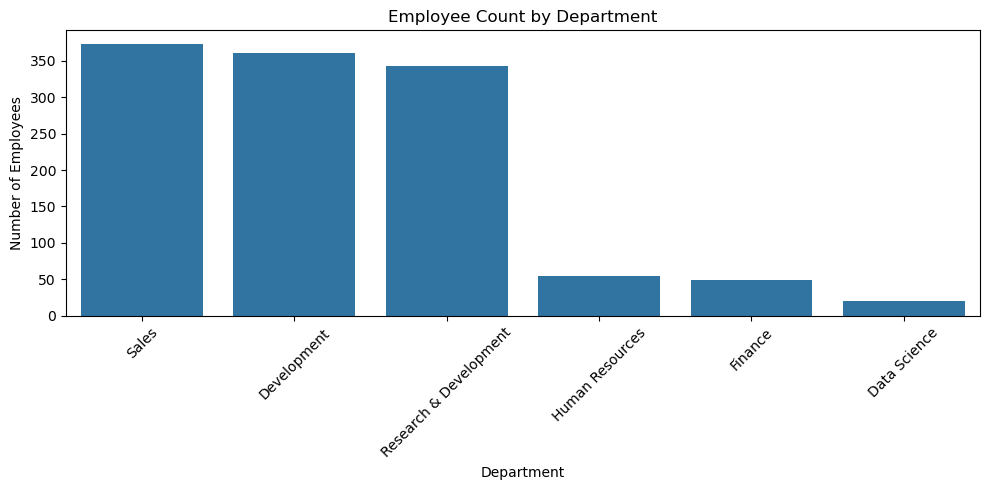

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="EmpDepartment",
    order=df["EmpDepartment"].value_counts().index
)

plt.title("Employee Count by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insights:** The Sales department has the highest number of employees, followed by Development and Research & Development. Data Science has the lowest employee count. Employee distribution varies considerably across departments, which should be considered when comparing their performance.

### 2. Average Performance Rating by Department

This graph compares the average employee performance rating across departments to identify differences in their average ratings.

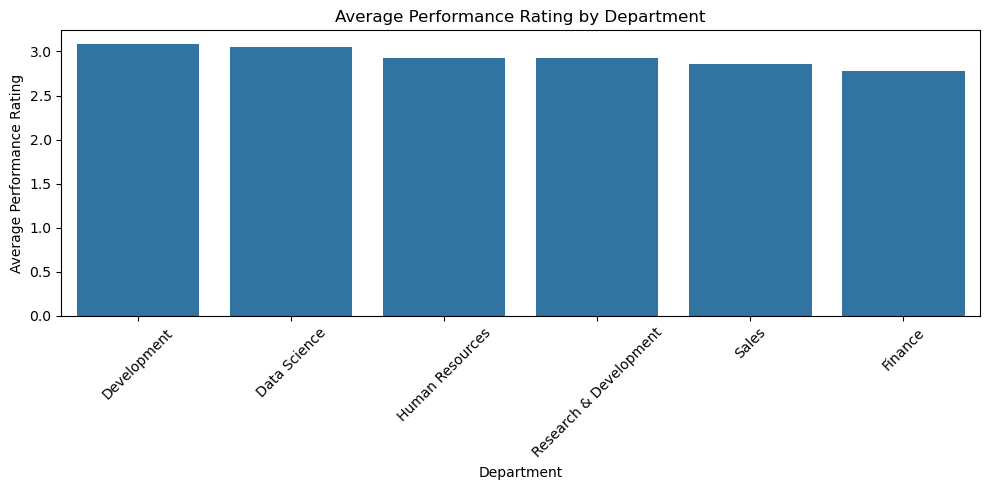

In [10]:
department_avg_rating = (
    df.groupby("EmpDepartment")["PerformanceRating"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=department_avg_rating.index,
    y=department_avg_rating.values
)

plt.title("Average Performance Rating by Department")
plt.xlabel("Department")
plt.ylabel("Average Performance Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Insights — Average Performance Rating by Department

The Development department has the highest average performance rating, followed by Data Science. Finance has the lowest average rating, while Sales is also relatively lower than most departments. These differences suggest that HR could investigate department-specific factors and identify opportunities to support employee performance. However, average ratings alone do not explain the reasons behind these differences.

### 3. Performance Rating Distribution

This graph shows the number of employees in each performance rating category and helps identify the distribution of the target variable.

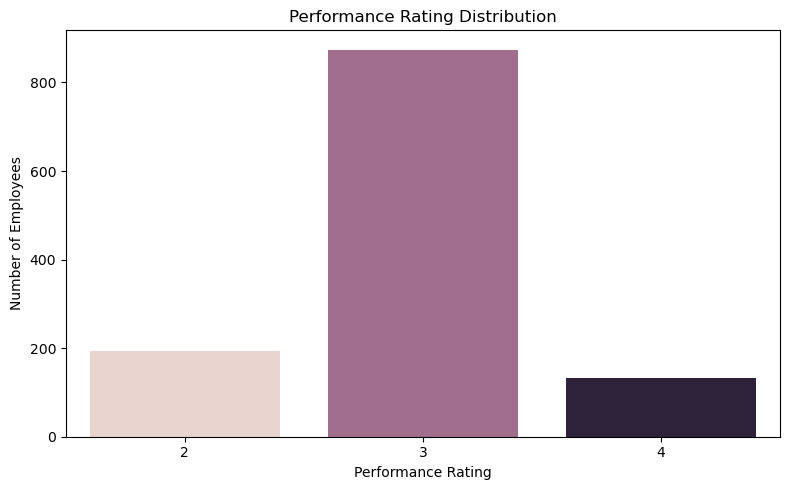

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="PerformanceRating",
    hue="PerformanceRating",
    order=[2, 3, 4],
    legend=False
)

plt.title("Performance Rating Distribution")
plt.xlabel("Performance Rating")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

### Insights — Performance Rating Distribution

Performance Rating 3 is the most common category, accounting for 72.83% of employees. Rating 2 represents 16.17%, while Rating 4 represents 11.00%. This indicates an imbalanced target variable, so model performance should be evaluated using macro F1-score, macro recall, and class-wise precision and recall in addition to accuracy.

### 4. Performance Rating by Department

This graph compares the number of employees receiving each performance rating across departments.

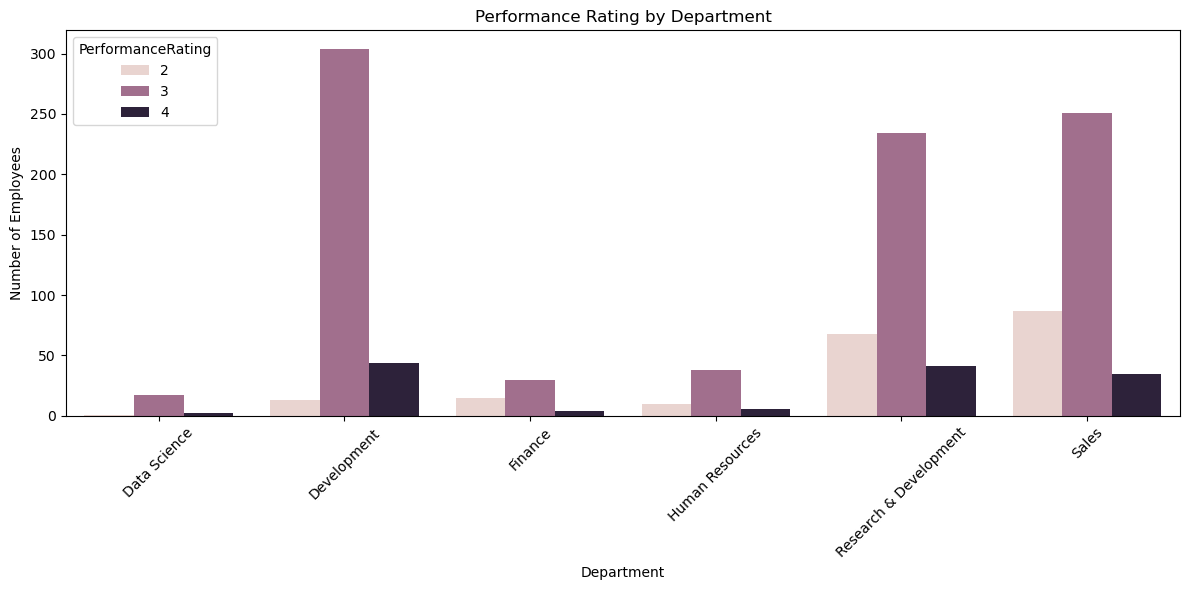

In [12]:
department_rating_counts = (
    df.groupby(["EmpDepartment", "PerformanceRating"])
    .size()
    .reset_index(name="EmployeeCount")
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=department_rating_counts,
    x="EmpDepartment",
    y="EmployeeCount",
    hue="PerformanceRating",
    hue_order=[2, 3, 4]
)

plt.title("Performance Rating by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Insights — Performance Rating by Department

Performance Rating 3 is the most common rating across all departments. Development has the highest number of employees with Rating 3, while Sales and Research & Development also have relatively large counts. Finance and Human Resources have fewer employees overall, so raw counts should be interpreted alongside department size. These results describe the observed distribution and do not explain the causes of performance differences.

### 5. Performance Rating Percentage by Department

This graph compares the percentage of employees in each performance rating category within every department, allowing a fairer comparison across departments of different sizes.

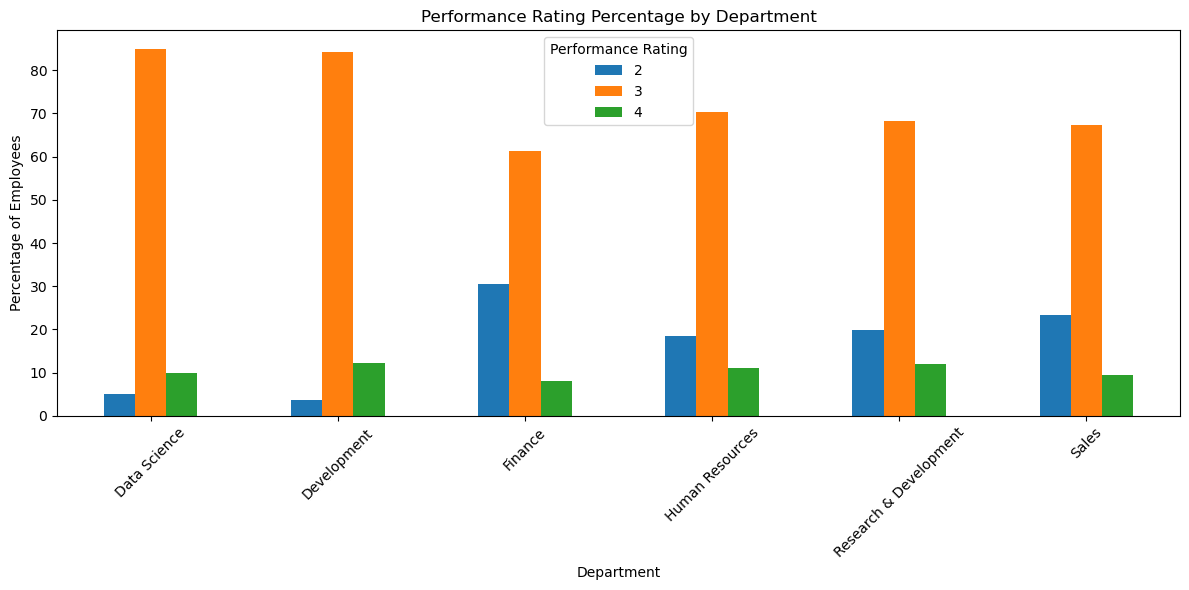

In [13]:
department_percentage = pd.crosstab(
    df["EmpDepartment"],
    df["PerformanceRating"],
    normalize="index"
) * 100

department_percentage = department_percentage.round(2)

department_percentage.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Rating Percentage by Department")
plt.xlabel("Department")
plt.ylabel("Percentage of Employees")
plt.xticks(rotation=45)
plt.legend(title="Performance Rating")
plt.tight_layout()
plt.show()

### Insights — Performance Rating Percentage by Department

Data Science and Development have the highest proportions of employees with Performance Rating 3, at approximately 85% and 84%, respectively. Finance has the highest proportion of Rating 2 employees, at approximately 31%. Rating 3 is the most common category in every department. These percentages help compare departments of different sizes, but they do not establish why performance ratings differ.

### 6. Job Satisfaction vs Performance Rating

This graph compares employee performance ratings across different job satisfaction levels to explore whether a relationship exists between job satisfaction and performance.

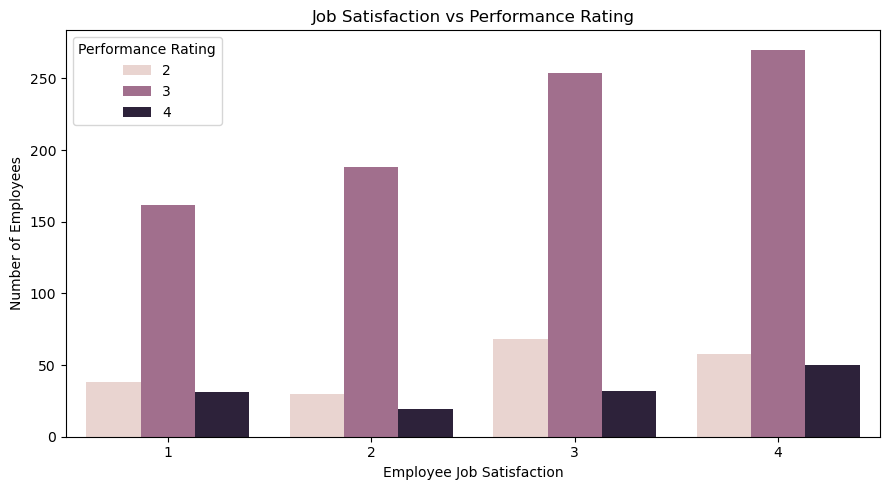

In [14]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="EmpJobSatisfaction",
    hue="PerformanceRating",
    hue_order=[2, 3, 4]
)

plt.title("Job Satisfaction vs Performance Rating")
plt.xlabel("Employee Job Satisfaction")
plt.ylabel("Number of Employees")
plt.legend(title="Performance Rating")
plt.tight_layout()
plt.show()

### Insights — Job Satisfaction vs Performance Rating

Performance Rating 3 is the most common category across all job satisfaction levels. The count of employees with Rating 3 is highest at satisfaction level 4. However, this graph shows employee counts rather than within-group percentages, so it does not establish that higher job satisfaction causes better performance.

### 7. Overtime vs Performance Rating

This graph compares employee performance ratings between employees who work overtime and those who do not.

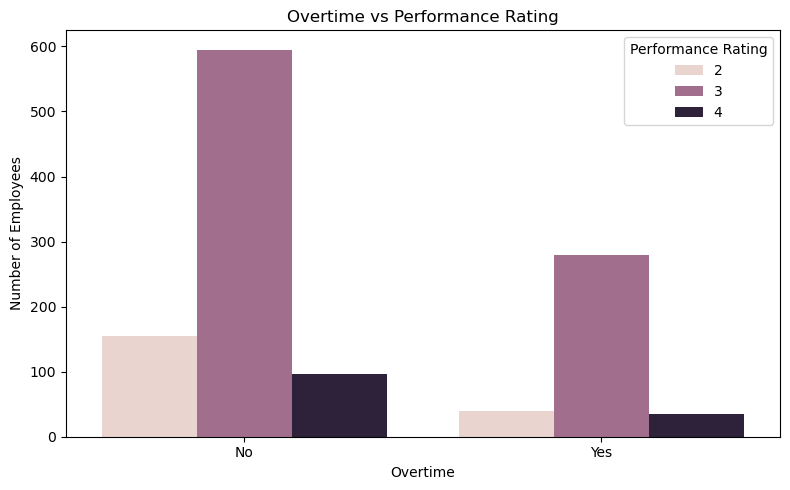

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="OverTime",
    hue="PerformanceRating",
    hue_order=[2, 3, 4]
)

plt.title("Overtime vs Performance Rating")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")
plt.legend(title="Performance Rating")
plt.tight_layout()
plt.show()

### Insights — Overtime vs Performance Rating

Performance Rating 3 is the most common category among both employees who work overtime and those who do not. The number of employees in the non-overtime group is much higher than in the overtime group. Therefore, counts alone are not sufficient to compare performance between these groups. Further analysis using within-group percentages would provide a fairer comparison.

### 8. Training Times vs Performance Rating

This graph compares employee performance ratings across different numbers of training sessions attended during the last year.

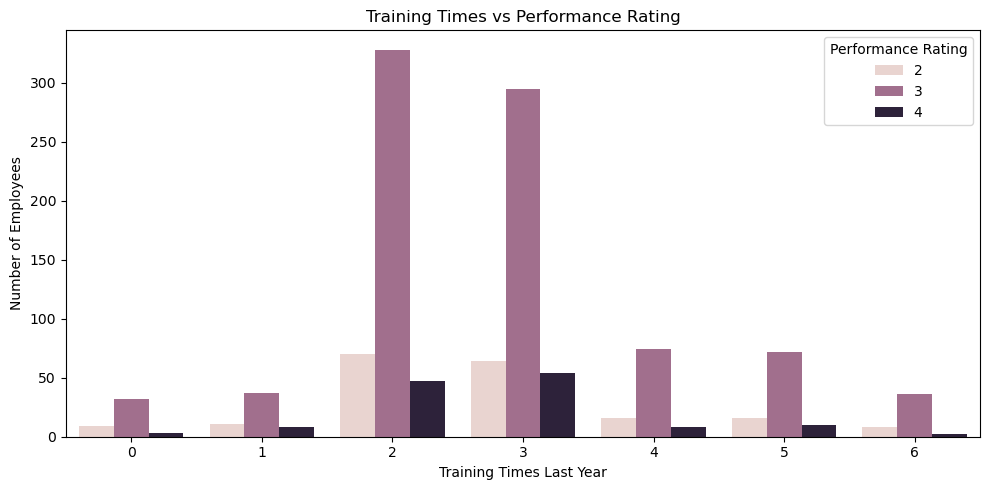

In [16]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="TrainingTimesLastYear",
    hue="PerformanceRating",
    hue_order=[2, 3, 4]
)

plt.title("Training Times vs Performance Rating")
plt.xlabel("Training Times Last Year")
plt.ylabel("Number of Employees")
plt.legend(title="Performance Rating")
plt.tight_layout()
plt.show()

### Insights — Training Times vs Performance Rating

Most employees attended training two or three times during the last year. Performance Rating 3 is the most common category across all training frequencies. However, this graph shows employee counts rather than within-group percentages, so it cannot establish that additional training causes better performance. Further analysis could compare rating percentages across training frequencies.

### 9. Job Involvement vs Performance Rating

This graph compares employee performance ratings across different job involvement levels.

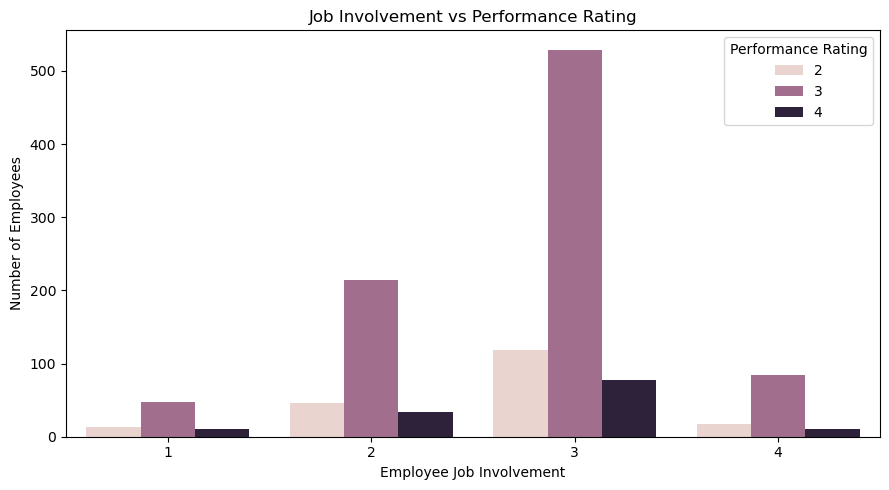

In [17]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="EmpJobInvolvement",
    hue="PerformanceRating",
    hue_order=[2, 3, 4]
)

plt.title("Job Involvement vs Performance Rating")
plt.xlabel("Employee Job Involvement")
plt.ylabel("Number of Employees")
plt.legend(title="Performance Rating")
plt.tight_layout()
plt.show()

### Insights — Job Involvement vs Performance Rating

Most employees have a job involvement level of 3, and Performance Rating 3 is the most common category across all involvement levels. Employee counts are highest at level 3, but this may partly reflect the larger number of employees in that group. Further analysis using percentages would help compare the groups fairly.

### 10. Work-Life Balance vs Performance Rating

This graph compares employee performance ratings across different work-life balance levels.

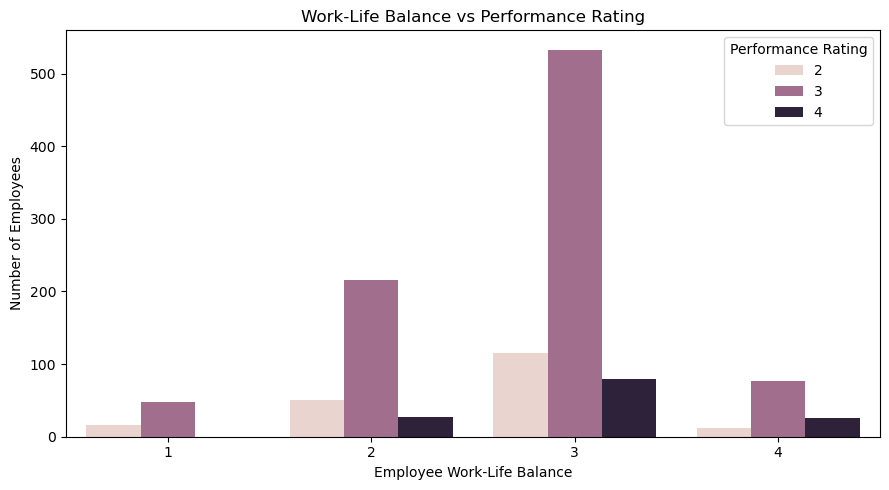

In [18]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="EmpWorkLifeBalance",
    hue="PerformanceRating",
    hue_order=[2, 3, 4]
)

plt.title("Work-Life Balance vs Performance Rating")
plt.xlabel("Employee Work-Life Balance")
plt.ylabel("Number of Employees")
plt.legend(title="Performance Rating")
plt.tight_layout()
plt.show()

### Insights — Work-Life Balance vs Performance Rating

Most employees have a work-life balance level of 3, and Performance Rating 3 is the most common category across all levels. The count of employees with Rating 4 appears higher at level 4 than at level 1. However, employee counts differ across groups, so percentages should be compared before drawing conclusions about the relationship between work-life balance and performance.

### 11. Salary Hike Percentage vs Performance Rating

This graph compares employee performance ratings across different last salary hike percentages.

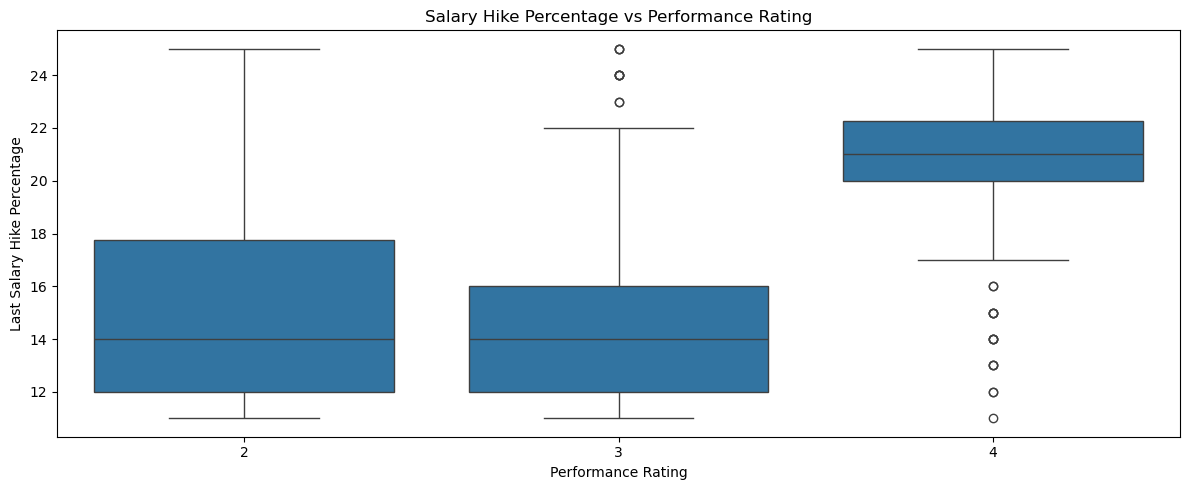

In [19]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df,
    x="PerformanceRating",
    y="EmpLastSalaryHikePercent"
)

plt.title("Salary Hike Percentage vs Performance Rating")
plt.xlabel("Performance Rating")
plt.ylabel("Last Salary Hike Percentage")
plt.tight_layout()
plt.show()

### 12. Years Since Last Promotion vs Performance Rating

This graph compares the time since an employee's last promotion with their performance rating.

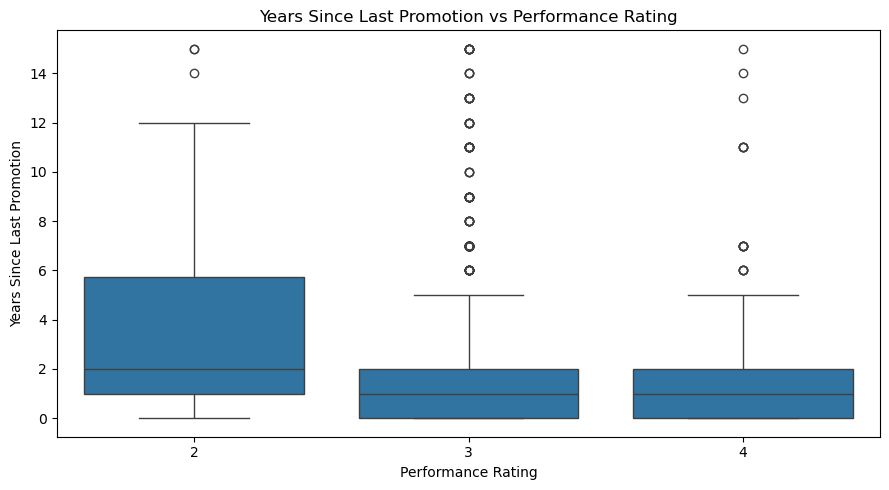

In [20]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="PerformanceRating",
    y="YearsSinceLastPromotion"
)

plt.title("Years Since Last Promotion vs Performance Rating")
plt.xlabel("Performance Rating")
plt.ylabel("Years Since Last Promotion")
plt.tight_layout()
plt.show()

### 13. Age vs Performance Rating

This graph compares employee age distributions across different performance rating categories.

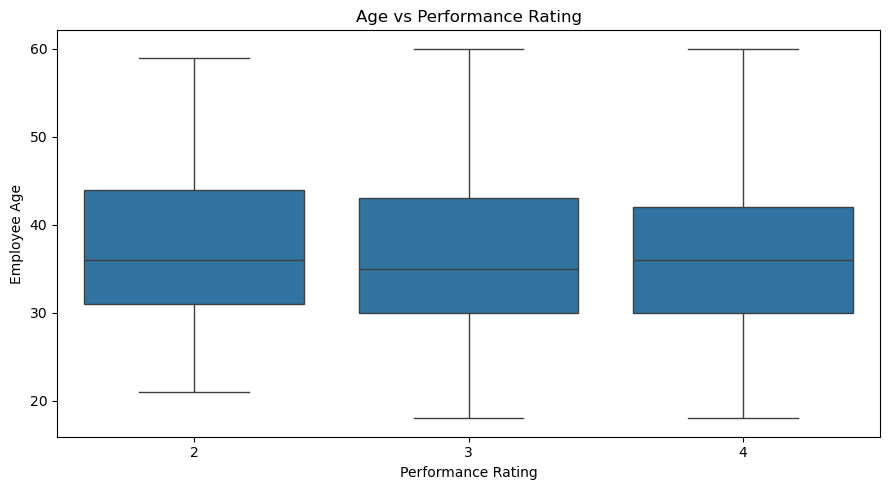

In [21]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="PerformanceRating",
    y="Age"
)

plt.title("Age vs Performance Rating")
plt.xlabel("Performance Rating")
plt.ylabel("Employee Age")
plt.tight_layout()
plt.show()

### 14. Age vs Total Work Experience

This scatter plot explores the relationship between employee age and total work experience.

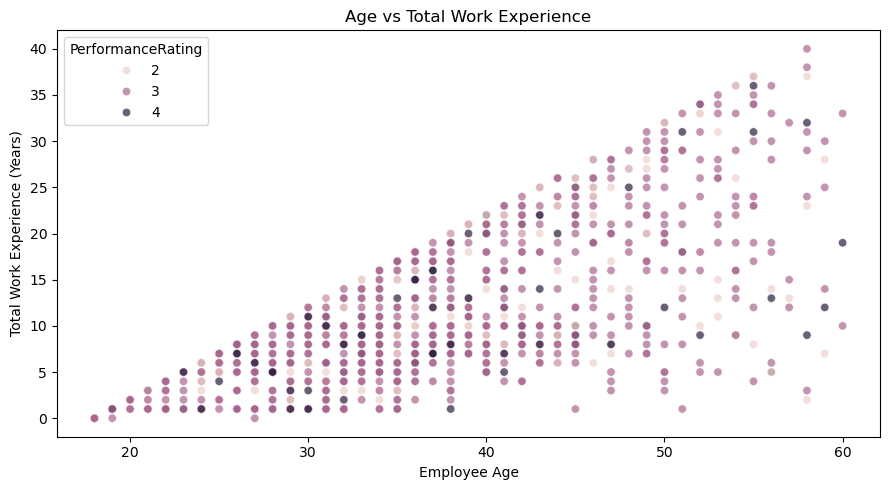

In [22]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="TotalWorkExperienceInYears",
    hue="PerformanceRating",
    alpha=0.7
)

plt.title("Age vs Total Work Experience")
plt.xlabel("Employee Age")
plt.ylabel("Total Work Experience (Years)")
plt.tight_layout()
plt.show()

### 15. Years at Current Company vs Performance Rating

This box plot compares employee tenure at the current company across performance rating categories.

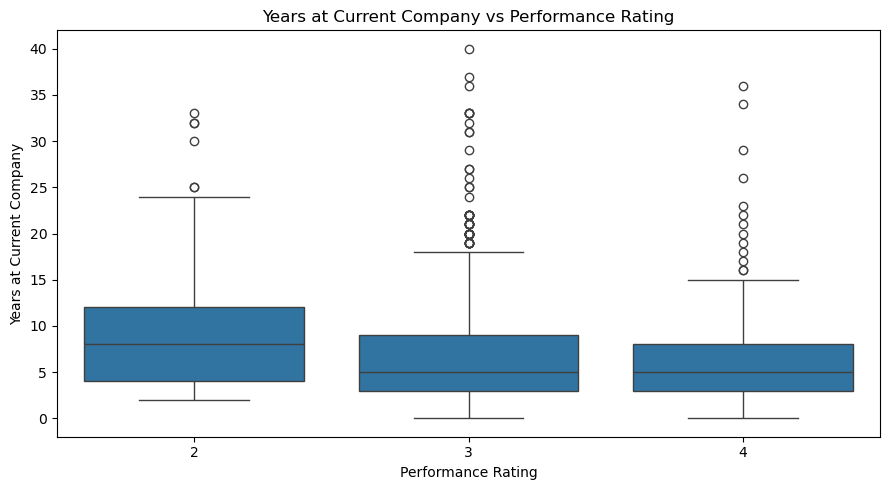

In [23]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="PerformanceRating",
    y="ExperienceYearsAtThisCompany"
)

plt.title("Years at Current Company vs Performance Rating")
plt.xlabel("Performance Rating")
plt.ylabel("Years at Current Company")
plt.tight_layout()
plt.show()

### 16. Experience Years in Current Role vs Performance Rating

This box plot compares the number of years employees have spent in their current role across performance rating categories.

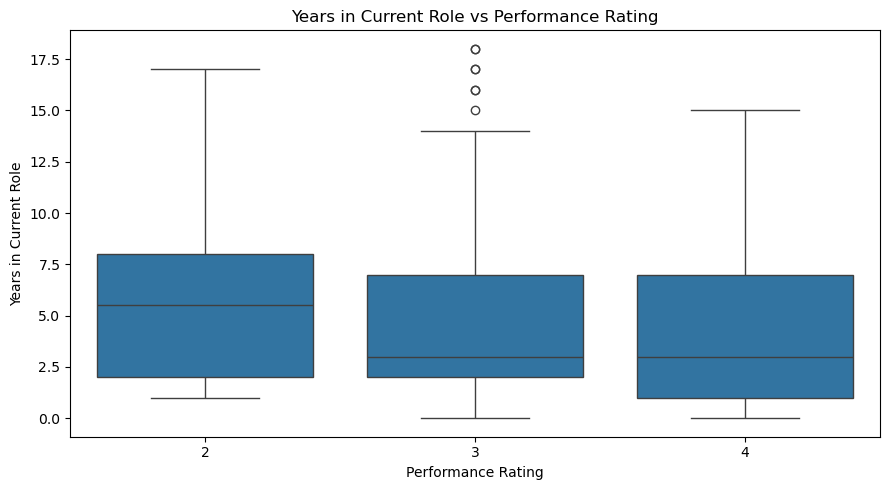

In [24]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="PerformanceRating",
    y="ExperienceYearsInCurrentRole"
)

plt.title("Years in Current Role vs Performance Rating")
plt.xlabel("Performance Rating")
plt.ylabel("Years in Current Role")
plt.tight_layout()
plt.show()

### 17. Years With Current Manager vs Performance Rating

This box plot compares the number of years employees have worked with their current manager across different performance rating categories. It helps us explore whether manager tenure varies across performance ratings.

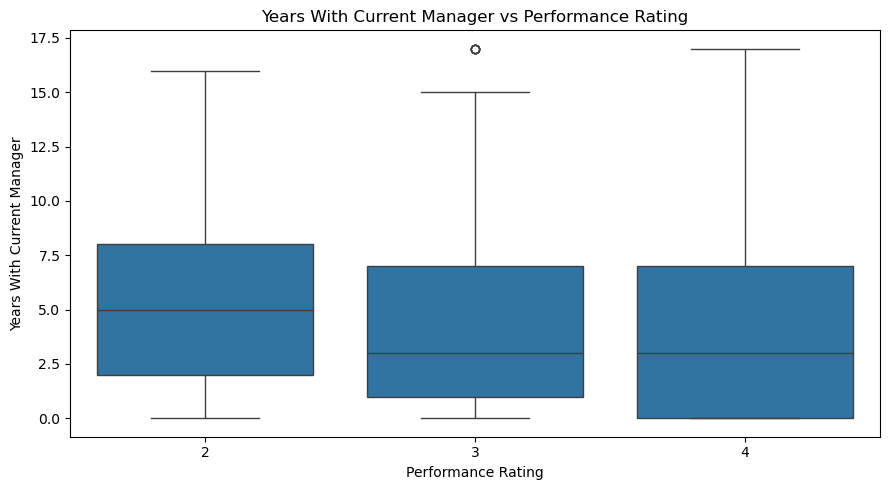

In [25]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="PerformanceRating",
    y="YearsWithCurrManager"
)

plt.title("Years With Current Manager vs Performance Rating")
plt.xlabel("Performance Rating")
plt.ylabel("Years With Current Manager")

plt.tight_layout()
plt.show()

### 18. Environment Satisfaction vs Performance Rating

This count plot compares employee performance ratings across different work environment satisfaction levels. It helps us explore how performance ratings are distributed across these groups. The plot shows association in the data, not proof of causation.

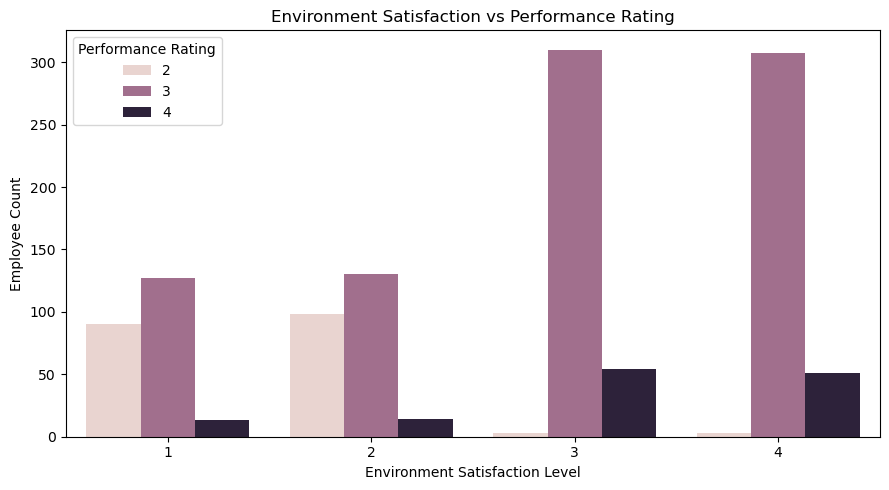

In [26]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="EmpEnvironmentSatisfaction",
    hue="PerformanceRating"
)

plt.title("Environment Satisfaction vs Performance Rating")
plt.xlabel("Environment Satisfaction Level")
plt.ylabel("Employee Count")
plt.legend(title="Performance Rating")

plt.tight_layout()
plt.show()

### 19. Relationship Satisfaction vs Performance Rating

This count plot compares employee performance ratings across different relationship satisfaction levels. It helps us explore the distribution of performance ratings among these groups. The observed relationship does not prove causation.

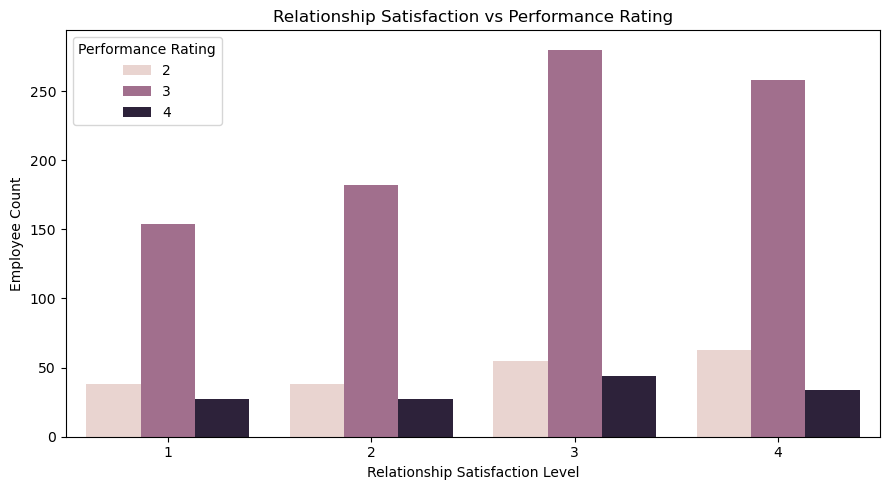

In [27]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="EmpRelationshipSatisfaction",
    hue="PerformanceRating"
)

plt.title("Relationship Satisfaction vs Performance Rating")
plt.xlabel("Relationship Satisfaction Level")
plt.ylabel("Employee Count")
plt.legend(title="Performance Rating")

plt.tight_layout()
plt.show()

### 20. Job Level vs Performance Rating

This count plot compares employee performance ratings across different job levels. It helps us explore how performance ratings are distributed among employees at different levels. Employee counts may differ across job levels, so the chart does not establish causation.

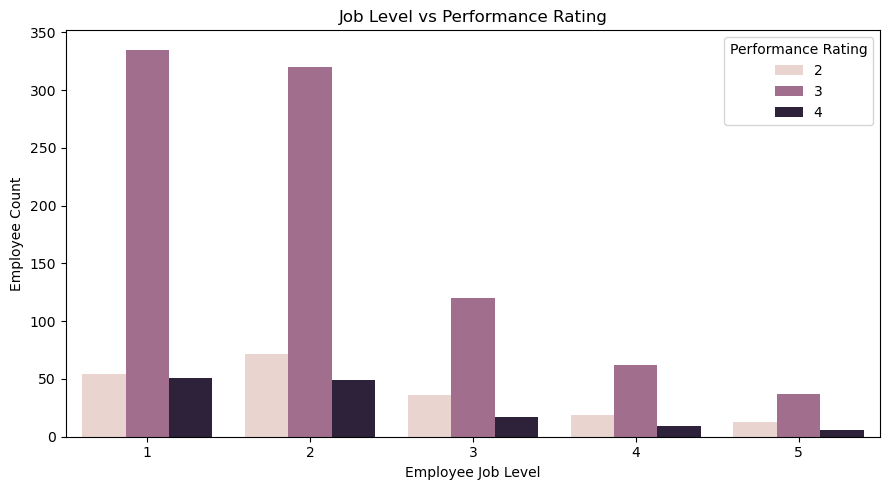

In [28]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="EmpJobLevel",
    hue="PerformanceRating"
)

plt.title("Job Level vs Performance Rating")
plt.xlabel("Employee Job Level")
plt.ylabel("Employee Count")
plt.legend(title="Performance Rating")

plt.tight_layout()
plt.show()

In [29]:
department_percentage = pd.crosstab(
    df["EmpDepartment"],
    df["PerformanceRating"],
    normalize="index"
) * 100

department_percentage = department_percentage.round(2)

display(department_percentage)

PerformanceRating,2,3,4
EmpDepartment,,,
Data Science,5.00,85.00,10.00
Development,3.60,84.21,12.19
Finance,30.61,61.22,8.16
Human Resources,18.52,70.37,11.11
Research & Development,19.83,68.22,11.95
Sales,23.32,67.29,9.38


### Department-wise Performance Rating Percentage — Insights

- **Data Science:** 85% of employees received Rating 3, while 10% received Rating 4.
- **Development:** 84.21% received Rating 3, and 12.19% received Rating 4.
- **Finance:** Rating 2 accounts for 30.61%, the highest proportion among all departments.
- **Human Resources:** 70.37% received Rating 3.
- **Research & Development:** 68.22% received Rating 3, while 19.83% received Rating 2.
- **Sales:** 67.29% received Rating 3, and 23.32% received Rating 2.

**Conclusion:** Rating 3 is the most common performance rating in every department. Data Science and Development have relatively high proportions of Rating 3 and lower proportions of Rating 2. Finance has the highest proportion of Rating 2 employees, followed by Sales. HR may investigate department-specific factors and provide appropriate support to improve employee performance.

### Numerical Features and Performance Rating

This analysis examines the correlation between numerical features and employee performance ratings to identify possible relationships in the dataset.

In [30]:
numerical_df = df.select_dtypes(include=["number"])

correlation_with_rating = (
    numerical_df.corr()["PerformanceRating"]
    .drop("PerformanceRating")
    .sort_values(ascending=False)
)

display(correlation_with_rating)

EmpEnvironmentSatisfaction      0.395561
EmpLastSalaryHikePercent        0.333722
EmpWorkLifeBalance              0.124429
NumCompaniesWorked              0.020980
EmpEducationLevel               0.020529
EmpJobSatisfaction              0.000606
TrainingTimesLastYear          -0.005443
EmpJobInvolvement              -0.010539
EmpRelationshipSatisfaction    -0.019502
Age                            -0.040164
EmpHourlyRate                  -0.043116
DistanceFromHome               -0.046142
TotalWorkExperienceInYears     -0.068141
EmpJobLevel                    -0.076632
ExperienceYearsAtThisCompany   -0.111645
YearsWithCurrManager           -0.122313
ExperienceYearsInCurrentRole   -0.147638
YearsSinceLastPromotion        -0.167629
Name: PerformanceRating, dtype: float64

### Numerical Features and Performance Rating — Insights

- **Employee Environment Satisfaction (0.396):** Shows the strongest positive correlation with Performance Rating among the numerical features.
- **Employee Last Salary Hike Percentage (0.334):** Shows a moderate positive correlation with performance rating.
- **Employee Work-Life Balance (0.124):** Shows a weak positive correlation.
- **Years Since Last Promotion (-0.168):** Shows the strongest negative correlation among the numerical features.
- **Experience Years in Current Role (-0.148):** Shows a weak negative correlation.
- Most other numerical features have correlations close to zero, indicating weak linear relationships with Performance Rating.

**Conclusion:** Employee Environment Satisfaction and Employee Last Salary Hike Percentage have the strongest positive correlations with performance rating in this analysis. Years Since Last Promotion has a negative correlation. These are associations, not proof of cause and effect; other factors may also influence performance ratings.

### Correlation Heatmap

A correlation heatmap visualizes relationships between numerical features. It helps identify strongly correlated variables and possible multicollinearity before model building.

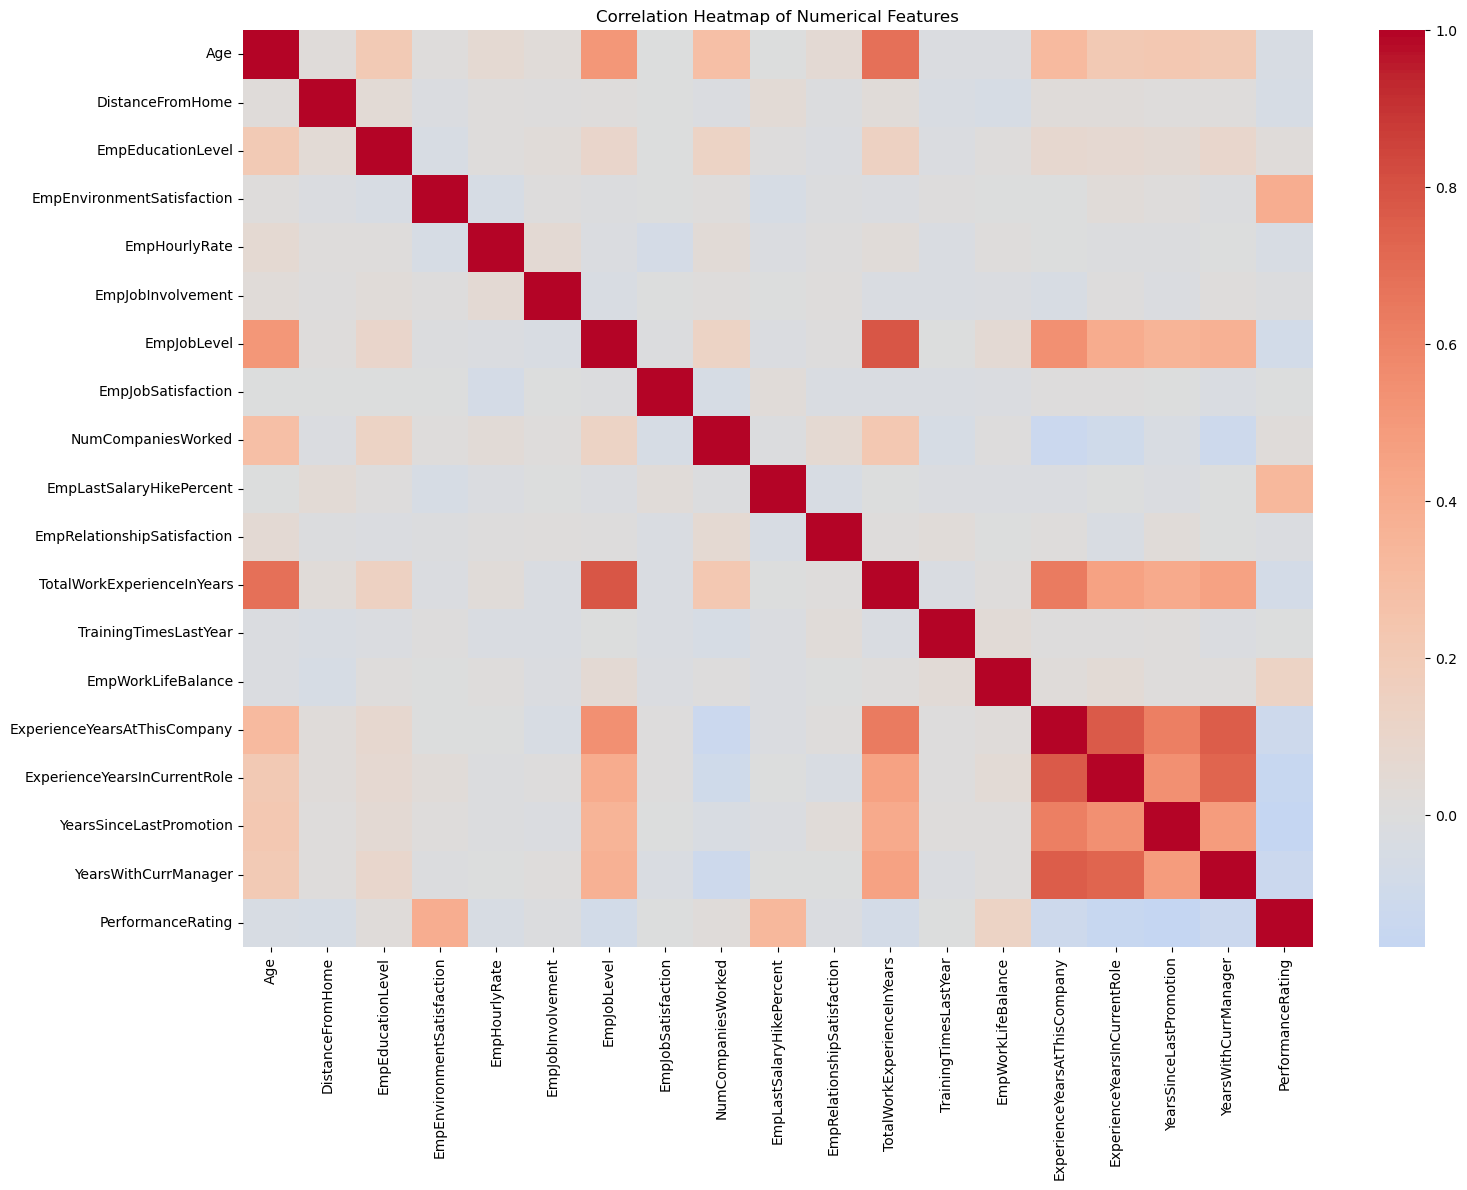

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_df = df.select_dtypes(include=["number"])

plt.figure(figsize=(16, 12))

sns.heatmap(
    numerical_df.corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

### Correlation Heatmap — Insights

- **Employee Environment Satisfaction** shows a positive correlation with Performance Rating.
- **Employee Last Salary Hike Percentage** also shows a positive correlation with Performance Rating.
- **Experience Years in Current Role, Years Since Last Promotion, and Years With Current Manager** show negative correlations with Performance Rating.
- Several experience-related features are positively correlated with one another, especially Experience Years at This Company and Experience Years in Current Role.
- Most other numerical feature pairs show weak correlations.

**Conclusion:** The heatmap highlights relationships among numerical features and Performance Rating. Experience-related variables are correlated with each other, so multicollinearity may need to be checked when using models sensitive to correlated features. Correlation alone does not establish causation.

## EDA Summary

The dataset contains **1,200 employee records and 28 columns**. Initial data-quality checks identified no missing values or duplicate records.

### Key Findings

1. **Department Performance:** Development has the highest average performance rating (3.09), while Finance has the lowest (2.78).

2. **Performance Rating Distribution:** Rating 3 is the majority class, with 874 employees (72.83%). Rating 2 accounts for 194 employees (16.17%), while Rating 4 accounts for 132 employees (11.00%). This indicates class imbalance in the target variable.

3. **Department-wise Analysis:** Rating 3 is the most common category across departments. Department-wise percentages provide a fairer comparison because department sizes differ.

4. **Employee Satisfaction:** Environment satisfaction, job satisfaction, relationship satisfaction, and work-life balance were explored to understand their association with performance ratings.

5. **Training and Work Factors:** Overtime, training frequency, and job involvement were compared across performance rating categories.

6. **Career and Experience Factors:** Age, total work experience, years at the company, years in the current role, years with the current manager, time since last promotion, salary hike percentage, and job level were explored.

7. **Correlation Analysis:** Numerical correlations were examined to identify possible relationships between numerical features and performance rating. Correlation does not establish causation.

### Conclusion

EDA provides an overview of employee characteristics and performance rating patterns. Because the target variable is imbalanced, model evaluation should consider accuracy, macro F1-score, macro recall, and class-wise precision and recall. These findings guide the preprocessing and model-building stages.

In [32]:
# Separate features and target

x = df.drop(columns=["PerformanceRating", "EmpNumber"])
y = df["PerformanceRating"]

print("Features shape:", x.shape)
print("Target shape:", y.shape)

Features shape: (1200, 26)
Target shape: (1200,)


In [33]:
print("\nTarget Distribution:")
print(y.value_counts().sort_index())


Target Distribution:
PerformanceRating
2    194
3    874
4    132
Name: count, dtype: int64


In [34]:
print("EmpNumber in x:","EmpNumber" in x.columns)
print("Total columns in x:",x.shape[1])
print("EmpNumber in df:","EmpNumber" in df.columns)

EmpNumber in x: False
Total columns in x: 26
EmpNumber in df: True


In [35]:
# Identify Categorical columns
categorical_col=x.select_dtypes(include=["object"]).columns.tolist()
print("categorical_col:",categorical_col)
print("Total categorical_col:",len(categorical_col))

categorical_col: ['Gender', 'EducationBackground', 'MaritalStatus', 'EmpDepartment', 'EmpJobRole', 'BusinessTravelFrequency', 'OverTime', 'Attrition']
Total categorical_col: 8


In [36]:
# Identify Numerical columns
Numerical_col=x.select_dtypes(include=np.number).columns.tolist()
print("Numerical_col:",Numerical_col)
print("Total Numerical col:",len(Numerical_col))

Numerical_col: ['Age', 'DistanceFromHome', 'EmpEducationLevel', 'EmpEnvironmentSatisfaction', 'EmpHourlyRate', 'EmpJobInvolvement', 'EmpJobLevel', 'EmpJobSatisfaction', 'NumCompaniesWorked', 'EmpLastSalaryHikePercent', 'EmpRelationshipSatisfaction', 'TotalWorkExperienceInYears', 'TrainingTimesLastYear', 'EmpWorkLifeBalance', 'ExperienceYearsAtThisCompany', 'ExperienceYearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Total Numerical col: 18


In [37]:
# check target class distribution
print("performance rating counts:")
print(y.value_counts().sort_index())
print("\nperformance rating percentage:")
print((y.value_counts(normalize=True).sort_index()*100).round(2))

performance rating counts:
PerformanceRating
2    194
3    874
4    132
Name: count, dtype: int64

performance rating percentage:
PerformanceRating
2    16.17
3    72.83
4    11.00
Name: proportion, dtype: float64


#### Target is imbalanced

### Train-test split

In [38]:
from sklearn.model_selection import train_test_split

In [39]:
x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("x_train shape:",x_train.shape)
print("x_test shape:", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:",y_test.shape)

x_train shape: (960, 26)
x_test shape: (240, 26)
y_train shape: (960,)
y_test shape: (240,)


In [40]:
categorical_col=x_train.select_dtypes(include=["object"]).columns.tolist()
Numerical_col=x_train.select_dtypes(include=np.number).columns.tolist()
print("categorical_col:",len(categorical_col))
print("Numerical_col:",len(Numerical_col))
print("Total col:",len(categorical_col) + len(Numerical_col))

categorical_col: 8
Numerical_col: 18
Total col: 26


## Machine Learning model Training

## 8. Model Building — Logistic Regression

### Objective
The objective of this step is to build a baseline classification model to predict employee performance ratings using employee-related features.

### Why Logistic Regression?
Logistic Regression is a supervised machine learning algorithm used for classification problems. In this project, it predicts one of three performance rating classes: 2, 3, or 4.

It is selected as the baseline model because it is simple, computationally efficient, and provides a reference for comparing other classification algorithms.

### Preprocessing
A `ColumnTransformer` is used to preprocess the input features:
- **StandardScaler:** Scales numerical features.
- **OneHotEncoder:** Converts categorical features into numerical representations.

A `Pipeline` combines preprocessing and Logistic Regression to ensure that the same transformations are applied consistently during training and prediction.

### Model Training
The model is trained using 80% of the dataset. The remaining 20% is reserved for testing. Stratified splitting maintains the original target-class proportions in both sets.

### Evaluation
The model is evaluated using Accuracy, Precision, Recall, F1-score, and a Confusion Matrix. Macro F1-score and class-wise Recall are especially useful because the target classes are imbalanced.

In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

preprocessor=ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),Numerical_col),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_col)
    ]
)
print("preprocessor created successfully")

preprocessor created successfully


In [42]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

In [43]:
logistic_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [44]:
y_pred = logistic_pipeline.predict(x_test)    # model predicted employee performance

In [45]:
y_pred[:10]

array([3, 3, 3, 3, 3, 3, 3, 3, 3, 3])

In [46]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test,y_pred)
print("Accuracy:", accuracy)
print("Accuracy:", accuracy*100, "%")

Accuracy: 0.825
Accuracy: 82.5 %


In [47]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           2       0.61      0.49      0.54        39
           3       0.86      0.93      0.89       175
           4       0.84      0.62      0.71        26

    accuracy                           0.82       240
   macro avg       0.77      0.68      0.72       240
weighted avg       0.82      0.82      0.82       240



In [48]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test,y_pred)
print(cm)

[[ 19  19   1]
 [ 10 163   2]
 [  2   8  16]]


###  — Normal Logistic Regression

The baseline Logistic Regression model achieved an accuracy of **82.50%** and a Macro F1-score of **0.7157**.

- **Rating 2:** Recall = 0.49
- **Rating 3:** Recall = 0.93
- **Rating 4:** Recall = 0.62

The model performs well in identifying employees with Rating 3, which is the majority class. However, its Recall for Ratings 2 and 4 is comparatively lower.

These results indicate that the baseline model has good overall accuracy but may need improvement in identifying the minority classes.

### Experiment: Logistic Regression with Balanced Class Weights

The target variable, `PerformanceRating`, has an imbalanced class distribution. To investigate its effect on model performance, a second Logistic Regression model is trained using `class_weight="balanced"`.

This setting automatically adjusts class weights inversely to their frequencies in the training data. It can help the model pay more attention to minority classes.

The balanced model is compared with the baseline using Accuracy, Macro F1-score, Macro Recall, and class-wise Recall. Balancing is treated as an experiment rather than an automatic improvement.

In [49]:
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

In [50]:
lr_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [51]:
y_b_pred = lr_pipeline.predict(x_test)
y_b_pred[:10]

array([3, 3, 3, 2, 3, 3, 3, 3, 3, 3])

In [52]:
accuracy= accuracy_score(y_test,y_b_pred)
print("Accuracy:", accuracy)
print("Accuracy:", accuracy*100,"%")

Accuracy: 0.7583333333333333
Accuracy: 75.83333333333333 %


In [53]:
print(classification_report(y_test,y_b_pred))

              precision    recall  f1-score   support

           2       0.49      0.74      0.59        39
           3       0.92      0.76      0.83       175
           4       0.54      0.77      0.63        26

    accuracy                           0.76       240
   macro avg       0.65      0.76      0.69       240
weighted avg       0.81      0.76      0.77       240



In [54]:
cm = confusion_matrix(y_test,y_b_pred)
print(cm)

[[ 29   7   3]
 [ 28 133  14]
 [  2   4  20]]


In [55]:
from sklearn.metrics import accuracy_score,f1_score,recall_score

print("Normal Logistic Regression")
print("Accuracy:",round(accuracy_score(y_test,y_pred),4))
print("Macro F1", round(f1_score(y_test,y_pred,average="macro"), 4))
print("Macro Recall",round(recall_score(y_test,y_pred,average="macro"),4))


print("\nBalanced Logistic Regression")
print("Accuracy:",round(accuracy_score(y_test,y_b_pred),4))
print("Macro F1", round(f1_score(y_test,y_b_pred,average="macro"), 4))
print("Macro Recall",round(recall_score(y_test,y_b_pred,average="macro"),4))

     

Normal Logistic Regression
Accuracy: 0.825
Macro F1 0.7157
Macro Recall 0.678

Balanced Logistic Regression
Accuracy: 0.7583
Macro F1 0.6869
Macro Recall 0.7576


### Comparison of Logistic Regression Models

| Metric | Normal Model | Balanced Model |
|---|---:|---:|
| Accuracy | 82.50% | 75.83% |
| Macro F1-score | 0.7157 | 0.6869 |
| Macro Recall | 0.6780 | 0.7576 |

The normal Logistic Regression model achieved higher Accuracy and Macro F1-score. The balanced model achieved higher Macro Recall and improved Recall for the minority classes.

Therefore, the normal model is retained as the baseline for further comparison. The final model will be selected after evaluating additional algorithms and comparing their performance.

## 9. Model Building — Decision Tree Classifier

### Objective
The objective is to build a Decision Tree classification model to predict employee performance ratings.

### Why Decision Tree?
Decision Tree is a supervised machine learning algorithm that makes predictions using a sequence of feature-based rules. It can capture nonlinear relationships and is relatively easy to interpret.

### Model Training
The model uses the same training and testing datasets as Logistic Regression to ensure a fair comparison. The existing preprocessing pipeline handles numerical and categorical features.

### Evaluation
The model is evaluated using Accuracy, Macro F1-score, Macro Recall, and a Classification Report. Its performance will be compared with Logistic Regression to determine whether it improves employee performance rating prediction.

In [56]:
from sklearn.tree import DecisionTreeClassifier

dt_pipeline=Pipeline([
    ("preprocessor", preprocessor),
    ("model",DecisionTreeClassifier(random_state=42))
])

In [57]:
dt_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [58]:
y_pred_dt = dt_pipeline.predict(x_test)
print(y_pred_dt)

[3 3 3 3 3 3 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 2 3 3 3 3 4 3 3 3 3 4 3 3 3 3 3
 3 4 3 3 3 3 2 3 4 4 3 3 3 3 2 3 4 3 3 3 3 3 3 3 4 4 3 3 3 2 3 3 4 3 3 3 3
 3 3 3 3 3 3 3 2 3 3 3 2 3 3 3 3 3 3 4 3 3 3 3 3 2 3 3 3 3 3 3 3 2 2 3 2 3
 3 4 3 3 4 3 3 3 3 3 4 2 2 3 3 2 3 3 4 4 3 3 3 3 2 3 3 4 4 3 2 2 2 3 3 3 2
 3 4 3 3 3 3 3 4 3 2 3 3 3 3 3 3 3 3 3 3 3 3 4 2 3 2 3 3 3 3 2 3 3 3 3 3 3
 3 4 3 3 2 3 3 3 3 3 3 3 3 3 3 2 3 3 3 2 3 2 3 3 3 3 3 3 3 3 2 2 2 2 3 4 3
 2 4 3 3 3 2 3 3 3 3 3 3 3 2 3 3 3 2]


In [59]:
accuracy = accuracy_score(y_test,y_pred_dt)
print("Accuracy:", accuracy)
print("Accuracy:", accuracy*100,"%")

Accuracy: 0.8958333333333334
Accuracy: 89.58333333333334 %


In [60]:
print(classification_report(y_test,y_pred_dt))

              precision    recall  f1-score   support

           2       0.83      0.74      0.78        39
           3       0.91      0.95      0.93       175
           4       0.87      0.77      0.82        26

    accuracy                           0.90       240
   macro avg       0.87      0.82      0.84       240
weighted avg       0.89      0.90      0.89       240



In [61]:
cm_dt = confusion_matrix(y_test,y_pred_dt)
print(cm_dt)

[[ 29  10   0]
 [  6 166   3]
 [  0   6  20]]


### Results and Interpretation — Decision Tree Classifier

The Decision Tree Classifier achieved an accuracy of **89.58%**, a Macro F1-score of **0.84**, and a Macro Recall of **0.82**.

- **Rating 2:** Precision = 0.83, Recall = 0.74, F1-score = 0.78.
- **Rating 3:** Precision = 0.91, Recall = 0.95, F1-score = 0.93.
- **Rating 4:** Precision = 0.87, Recall = 0.77, F1-score = 0.82.

The model correctly predicted 215 out of 240 test observations. It performed well across all three performance-rating classes, including the minority classes.

Compared with both Logistic Regression models, the Decision Tree achieved higher Accuracy, Macro F1-score, and Macro Recall. Therefore, it is the best-performing model among the models evaluated so far.

Further evaluation is required before selecting the final model.

## 10. Model Building — Random Forest Classifier

### Objective
The objective is to build a Random Forest classification model to predict employee performance ratings.

### Why Random Forest?
Random Forest is a supervised machine learning algorithm that combines multiple Decision Trees to make predictions. It can capture complex patterns and may generalize better than a single Decision Tree.

### Model Training
The model uses the same training and testing datasets as the previous models to ensure a fair comparison. The existing preprocessing pipeline handles numerical and categorical features.

### Evaluation
The model is evaluated using Accuracy, Macro F1-score, Macro Recall, and a Classification Report. Its performance is compared with Logistic Regression and Decision Tree.

The training and testing scores will also be examined to check for possible overfitting.

In [62]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=200,random_state=42,n_jobs=-1))
])

In [63]:
rf_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [64]:
y_pred_rf = rf_pipeline.predict(x_test)
y_pred_rf[:10]

array([3, 3, 3, 2, 3, 3, 2, 3, 3, 3])

In [65]:
accuracy = accuracy_score(y_test,y_pred_rf)
print("Accuracy:", accuracy)
print("Accuracy:", accuracy*100,"%")

Accuracy: 0.8916666666666667
Accuracy: 89.16666666666667 %


In [66]:
print(classification_report(y_test,y_pred_rf))

              precision    recall  f1-score   support

           2       0.91      0.77      0.83        39
           3       0.88      0.98      0.93       175
           4       1.00      0.46      0.63        26

    accuracy                           0.89       240
   macro avg       0.93      0.74      0.80       240
weighted avg       0.90      0.89      0.88       240



In [67]:
cm_rf = confusion_matrix(y_test,y_pred_rf)
print(cm_rf)

[[ 30   9   0]
 [  3 172   0]
 [  0  14  12]]


### Results and Interpretation — Random Forest Classifier

The Random Forest Classifier achieved an accuracy of **89.17%**, a Macro F1-score of **0.80**, and a Macro Recall of **0.74**.

- **Rating 2:** Precision = 0.91, Recall = 0.77, F1-score = 0.83.
- **Rating 3:** Precision = 0.88, Recall = 0.98, F1-score = 0.93.
- **Rating 4:** Precision = 1.00, Recall = 0.46, F1-score = 0.63.

The model performs very well in identifying Rating 3. However, it misses several Rating 4 employees by predicting them as Rating 3.

Compared with the Decision Tree, Random Forest achieved slightly lower Accuracy, Macro F1-score, and Macro Recall. Therefore, the Decision Tree remains the best-performing model so far based on these test-set metrics.

## Additional Model Comparison

In [68]:
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("classifier", SVC())
])

In [69]:
svm_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [70]:
y_pred_svm = svm_pipeline.predict(x_test)
y_pred_svm[:10]

array([3, 3, 3, 3, 3, 3, 3, 3, 3, 3])

In [71]:
accuracy = accuracy_score(y_test,y_pred_svm)
print("Accuracy:", accuracy)
print("Accuracy:", accuracy*100,"%")

Accuracy: 0.8333333333333334
Accuracy: 83.33333333333334 %


In [72]:
print(classification_report(y_test,y_pred_svm))

              precision    recall  f1-score   support

           2       0.94      0.41      0.57        39
           3       0.82      0.98      0.90       175
           4       0.86      0.46      0.60        26

    accuracy                           0.83       240
   macro avg       0.87      0.62      0.69       240
weighted avg       0.85      0.83      0.81       240



In [73]:
cm_svm = confusion_matrix(y_test,y_pred_svm)
print(cm_svm)

[[ 16  23   0]
 [  1 172   2]
 [  0  14  12]]


### SVM Baseline Model — Conclusion

The SVM model achieved an accuracy of **83.33%**, a Macro F1-score of **0.69**, and a Macro Recall of **0.62**. It performed well for Rating 3 but struggled to identify Ratings 2 and 4. Therefore, its baseline performance is lower than that of the Decision Tree and Random Forest models.

In [74]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier",KNeighborsClassifier())
])

In [75]:
knn_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [76]:
y_pred_knn = knn_pipeline.predict(x_test)
y_pred_knn[:10]

array([3, 3, 3, 3, 3, 3, 3, 3, 3, 3])

In [77]:
accuracy = accuracy_score(y_test,y_pred_knn)
print("Accuracy:", accuracy)
print("Accuracy:", accuracy*100,"%")

Accuracy: 0.7625
Accuracy: 76.25 %


In [78]:
print(classification_report(y_test,y_pred_knn))

              precision    recall  f1-score   support

           2       0.50      0.21      0.29        39
           3       0.78      0.95      0.86       175
           4       0.80      0.31      0.44        26

    accuracy                           0.76       240
   macro avg       0.69      0.49      0.53       240
weighted avg       0.74      0.76      0.72       240



In [79]:
cm_knn = confusion_matrix(y_test,y_pred_knn)
print(cm_knn)

[[  8  31   0]
 [  6 167   2]
 [  2  16   8]]


### KNN Baseline Model — Conclusion

The KNN model achieved an accuracy of **76.25%**, a Macro F1-score of **0.53**, and a Macro Recall of **0.49**. It performed well for Rating 3 but struggled to identify Ratings 2 and 4. Its baseline performance is lower than the other models evaluated so far.

In [80]:
from sklearn.ensemble import GradientBoostingClassifier

gb_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("classifier", GradientBoostingClassifier(random_state=42))
])

In [81]:
gb_pipeline.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [82]:
y_pred_gb = gb_pipeline.predict(x_test)
y_pred_gb[:10]

array([3, 3, 3, 2, 3, 3, 2, 3, 3, 3])

In [83]:
accuracy = accuracy_score(y_test,y_pred_gb)
print("Accuracy:", accuracy)
print("Accuracy:", accuracy*100,"%")

Accuracy: 0.9291666666666667
Accuracy: 92.91666666666667 %


In [84]:
print(classification_report(y_test,y_pred_gb))

              precision    recall  f1-score   support

           2       0.89      0.85      0.87        39
           3       0.94      0.97      0.96       175
           4       0.91      0.77      0.83        26

    accuracy                           0.93       240
   macro avg       0.91      0.86      0.89       240
weighted avg       0.93      0.93      0.93       240



In [85]:
cm_gb = confusion_matrix(y_test,y_pred_gb)
print(cm_gb)

[[ 33   5   1]
 [  4 170   1]
 [  0   6  20]]


### Gradient Boosting Baseline Model — Conclusion

The Gradient Boosting model achieved an Accuracy of **92.92%**, a Macro F1-score of **0.89**, and a Macro Recall of **0.86**.

It performed well across all three performance rating classes. The recall was 0.85 for Rating 2, 0.97 for Rating 3, and 0.77 for Rating 4.

Among the baseline models evaluated so far, Gradient Boosting shows the strongest overall performance. However, further comparison and tuning are required before selecting the final model.

In [86]:
import pandas as pd 
from sklearn.metrics import accuracy_score,f1_score,recall_score

models = {
    "Logistic Regression": y_pred,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "SVM": y_pred_svm,
    "KNN": y_pred_knn,
    "Gradient Boosting": y_pred_gb,
    
}
results=[]
for name, predictions in models.items():
    results.append({
        "Model":name,
        "Accuracy":accuracy_score(y_test,predictions),
        "Macro F1":f1_score(y_test,predictions,average="macro"),
        "Macro recall":recall_score(y_test,predictions,average="macro")
        
    })

baseline_results= pd.DataFrame(results)
baseline_results=baseline_results.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

baseline_results.round(4)

,Model,Accuracy,Macro F1,Macro recall
0,Gradient Boosting,0.9292,0.8856,0.8623
1,Decision Tree,0.8958,0.8434,0.8205
2,Random Forest,0.8917,0.7982,0.7379
3,Logistic Regression,0.8250,0.7157,0.6780
4,SVM,0.8333,0.6891,0.6182
5,KNN,0.7625,0.5313,0.4890


## Overall Baseline Model Comparison — Conclusion

Six baseline classification models were evaluated: Logistic Regression, Decision Tree, Random Forest, SVM, KNN, and Gradient Boosting.

Among these models, **Gradient Boosting achieved the best overall performance**, with an accuracy of **92.92%**, a Macro F1-score of approximately **0.89**, and a Macro Recall of approximately **0.86**. It performed well across all three employee performance rating classes.

The Decision Tree model ranked second, achieving an accuracy of **89.58%** and a Macro F1-score of **0.8434**. Random Forest also performed well, while Logistic Regression and SVM showed moderate results. KNN had the lowest overall performance, particularly in identifying minority classes.

Overall, Gradient Boosting is the leading candidate for further evaluation and hyperparameter tuning. However, the final model will be selected after comparing tuned models and evaluating their performance across all rating classes.

##  Hyperparameter Tuning

In [87]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

# Gradient Boosting pipeline
gb_tune_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(random_state=42))
    ]
)

# Hyperparameter combinations to test
param_grid_gb = {
    "classifier__n_estimators": [100, 150],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_depth": [2, 3]
}

# GridSearchCV
grid_search_gb = GridSearchCV(
    estimator=gb_tune_pipeline,
    param_grid=param_grid_gb,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Train using training data only
grid_search_gb.fit(x_train, y_train)

print("Best Parameters:", grid_search_gb.best_params_)
print("Best Cross-Validation Macro F1:", round(grid_search_gb.best_score_, 4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}
Best Cross-Validation Macro F1: 0.8943


In [88]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report,
    confusion_matrix
)

# Best model selected by GridSearchCV
best_gb_model = grid_search_gb.best_estimator_

# Predict on unseen test data
y_pred_gb_tuned = best_gb_model.predict(x_test)

# Evaluation metrics
print("Tuned Gradient Boosting Results")
print("-" * 40)
print("Accuracy:", round(accuracy_score(y_test, y_pred_gb_tuned), 4))
print("Macro F1:", round(f1_score(y_test, y_pred_gb_tuned, average="macro"), 4))
print("Macro Recall:", round(recall_score(y_test, y_pred_gb_tuned, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb_tuned))

Tuned Gradient Boosting Results
----------------------------------------
Accuracy: 0.9292
Macro F1: 0.8856
Macro Recall: 0.8623

Classification Report:
              precision    recall  f1-score   support

           2       0.89      0.85      0.87        39
           3       0.94      0.97      0.96       175
           4       0.91      0.77      0.83        26

    accuracy                           0.93       240
   macro avg       0.91      0.86      0.89       240
weighted avg       0.93      0.93      0.93       240

Confusion Matrix:
[[ 33   5   1]
 [  4 170   1]
 [  0   6  20]]


### Tuned Gradient Boosting Model — Conclusion

The Gradient Boosting model was tuned using GridSearchCV with 5-fold cross-validation and Macro F1-score as the evaluation metric.

The best parameters were:
- `learning_rate`: 0.1
- `max_depth`: 3
- `n_estimators`: 100

On the test dataset, the tuned model achieved **92.92% Accuracy**, **0.8856 Macro F1-score**, and **0.8623 Macro Recall**.

The model performed well across all three performance rating classes. However, Rating 4 had a recall of 0.77, indicating that some high-performance employees were classified incorrectly.

Further comparison with other tuned models is needed before selecting the final model.

## Baseline vs Tuned comparison

In [89]:
comparison_gb = pd.DataFrame([
    {
        "Model": "Baseline Gradient Boosting",
        "Accuracy": accuracy_score(y_test, y_pred_gb),
        "Macro F1": f1_score(y_test, y_pred_gb, average="macro"),
        "Macro Recall": recall_score(y_test, y_pred_gb, average="macro")
    },
    {
        "Model": "Tuned Gradient Boosting",
        "Accuracy": accuracy_score(y_test, y_pred_gb_tuned),
        "Macro F1": f1_score(y_test, y_pred_gb_tuned, average="macro"),
        "Macro Recall": recall_score(y_test, y_pred_gb_tuned, average="macro")
    }
])

comparison_gb.round(4)

,Model,Accuracy,Macro F1,Macro Recall
0,Baseline Gradient Boosting,0.9292,0.8856,0.8623
1,Tuned Gradient Boosting,0.9292,0.8856,0.8623


In [90]:
print("Baseline and tuned predictions are identical:",
      (y_pred_gb == y_pred_gb_tuned).all())

print("Baseline correct predictions:",
      (y_test.to_numpy() == y_pred_gb).sum())

print("Tuned correct predictions:",
      (y_test.to_numpy() == y_pred_gb_tuned).sum())

Baseline and tuned predictions are identical: True
Baseline correct predictions: 223
Tuned correct predictions: 223


### Hyperparameter Tuning of Decision Tree

In [91]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

dt_tune_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ]
)

param_grid_dt = {
    "classifier__max_depth": [None, 5, 10, 15, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

grid_search_dt = GridSearchCV(
    estimator=dt_tune_pipeline,
    param_grid=param_grid_dt,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search_dt.fit(x_train, y_train)

print("Best Parameters:", grid_search_dt.best_params_)
print("Best CV Macro F1:", round(grid_search_dt.best_score_, 4))

Fitting 5 folds for each of 45 candidates, totalling 225 fits
Best Parameters: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 10}
Best CV Macro F1: 0.8786


In [92]:
# Get the best Decision Tree model
best_dt_model = grid_search_dt.best_estimator_

# Predict on test data
y_pred_dt_tuned = best_dt_model.predict(x_test)

# Evaluate the model
print("Tuned Decision Tree Results")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_test, y_pred_dt_tuned), 4))
print("Macro F1:", round(f1_score(y_test, y_pred_dt_tuned, average="macro"), 4))
print("Macro Recall:", round(recall_score(y_test, y_pred_dt_tuned, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt_tuned))

Tuned Decision Tree Results
----------------------------------------
Accuracy: 0.9375
Macro F1: 0.8996
Macro Recall: 0.8661

Classification Report:
              precision    recall  f1-score   support

           2       0.89      0.85      0.87        39
           3       0.94      0.98      0.96       175
           4       1.00      0.77      0.87        26

    accuracy                           0.94       240
   macro avg       0.94      0.87      0.90       240
weighted avg       0.94      0.94      0.94       240

Confusion Matrix:
[[ 33   6   0]
 [  3 172   0]
 [  1   5  20]]


In [93]:
from sklearn.metrics import accuracy_score, f1_score, recall_score
import pandas as pd

# Include all baseline and tuned model predictions
all_models = {
    "Baseline Logistic Regression": y_pred,
    "Baseline Decision Tree": y_pred_dt,
    "Baseline Random Forest": y_pred_rf,
    "Baseline SVM": y_pred_svm,
    "Baseline KNN": y_pred_knn,
    "Baseline Gradient Boosting": y_pred_gb,
    "Tuned Gradient Boosting": y_pred_gb_tuned,
    "Tuned Decision Tree": y_pred_dt_tuned
}

# Calculate evaluation metrics
comparison_results = []

for model_name, predictions in all_models.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro"
        )
    })

# Create table and rank by Macro F1
overall_comparison = pd.DataFrame(comparison_results)

overall_comparison = (
    overall_comparison
    .sort_values(
        by=["Macro F1", "Macro Recall", "Accuracy"],
        ascending=False
    )
    .reset_index(drop=True)
)

overall_comparison.round(4)

,Model,Accuracy,Macro F1,Macro Recall
0,Tuned Decision Tree,0.9375,0.8996,0.8661
1,Baseline Gradient Boosting,0.9292,0.8856,0.8623
2,Tuned Gradient Boosting,0.9292,0.8856,0.8623
3,Baseline Decision Tree,0.8958,0.8434,0.8205
4,Baseline Random Forest,0.8917,0.7982,0.7379
5,Baseline Logistic Regression,0.8250,0.7157,0.6780
6,Baseline SVM,0.8333,0.6891,0.6182
7,Baseline KNN,0.7625,0.5313,0.4890


## Final Model Selection

After comparing the baseline and tuned machine learning models, the **Tuned Decision Tree Classifier** was selected as the final model based on its overall evaluation performance.

The selected model achieved the following results on the test dataset:

- **Accuracy:** 93.75%
- **Macro F1-score:** 0.8996
- **Macro Recall:** 0.8661

The model was tuned using GridSearchCV. The best hyperparameters were:

- `max_depth = 5`
- `min_samples_leaf = 2`
- `min_samples_split = 10`

Macro F1-score and macro recall were considered alongside accuracy because the target variable, `PerformanceRating`, is imbalanced. Although the model performed well overall, the classification report should also be considered to understand its performance for each rating class.

In [94]:
import joblib
final_model = best_dt_model
joblib.dump(final_model, "final_employee_performance_model.pkl")
print("Final Model Saved Successfully")

Final Model Saved Successfully



## Feature Importance Analysis

Feature importance helps us identify which features contribute most to the model's predictions. We will use the selected Tuned Decision Tree model to identify the most important features for predicting employee performance ratings.

In [95]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get the trained Decision Tree classifier
dt_model = best_dt_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = best_dt_model.named_steps["preprocessor"].get_feature_names_out()

# Create feature importance table
feature_importance = pd.DataFrame({
    "feature":feature_names,
    "Importance":dt_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(by="Importance",ascending=False).reset_index(drop=True)

# Display top 15 features
feature_importance.head(15)


,feature,Importance
0,num__EmpEnvironmentSatisfaction,0.271357
1,num__EmpLastSalaryHikePercent,0.253893
2,num__YearsSinceLastPromotion,0.214173
3,cat__EmpDepartment_Development,0.110860
4,num__EmpWorkLifeBalance,0.049689
5,num__ExperienceYearsInCurrentRole,0.039723
6,num__ExperienceYearsAtThisCompany,0.021338
7,num__TotalWorkExperienceInYears,0.009386
8,num__NumCompaniesWorked,0.008029
9,num__EmpHourlyRate,0.007830


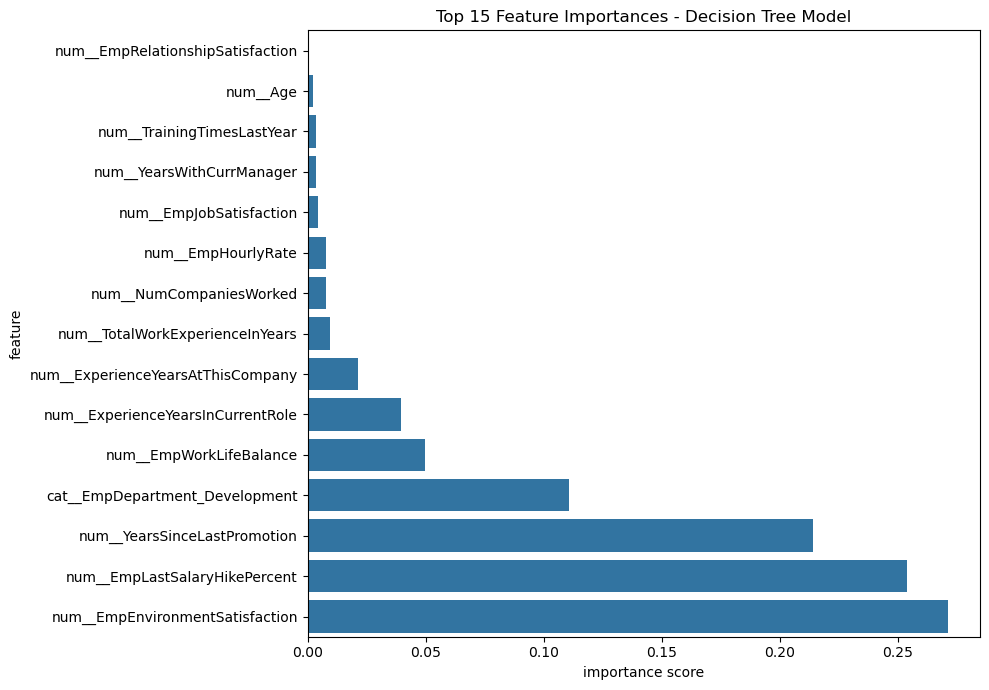

In [96]:
top_features = feature_importance.head(15).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(10,7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="feature"
)

plt.title("Top 15 Feature Importances - Decision Tree Model")
plt.xlabel("importance score")
plt.ylabel("feature")
plt.tight_layout()
plt.show()

### Feature Importance Analysis – Conclusion

The Tuned Decision Tree model found that Employee Environment Satisfaction, Salary Hike Percentage, and Time Since Last Promotion are the three most important features for predicting employee performance. The Development department and Work-Life Balance are also important.

**Business Implication:** HR teams can focus on employee satisfaction, fair salary hikes, and timely promotions to help improve employee performance. These results show patterns in the data but do not prove that these factors directly cause better performance.

## Final Model Evaluation

We evaluate the selected Tuned Decision Tree model using a confusion matrix and classification report to understand its prediction performance for each employee performance rating.

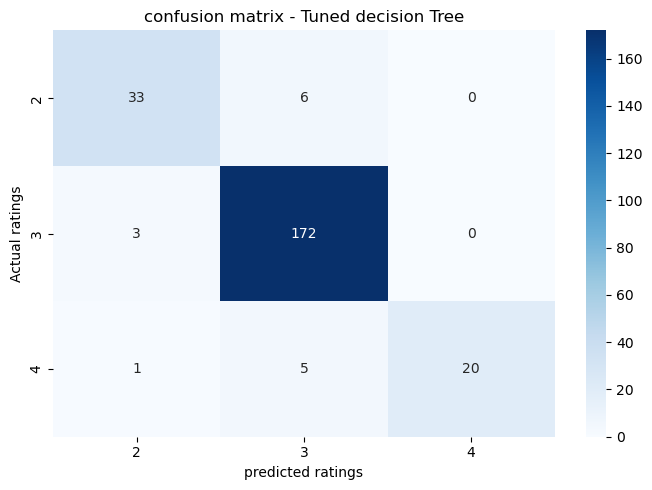

classification report:
              precision    recall  f1-score   support

           2       0.89      0.85      0.87        39
           3       0.94      0.98      0.96       175
           4       1.00      0.77      0.87        26

    accuracy                           0.94       240
   macro avg       0.94      0.87      0.90       240
weighted avg       0.94      0.94      0.94       240



In [97]:
from sklearn.metrics import confusion_matrix,classification_report
import matplotlib.pyplot as plt
import seaborn as sns

y_pred_final = best_dt_model.predict(x_test)

cm = confusion_matrix(y_test,y_pred_final)

plt.figure(figsize=(7,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_dt_model.classes_,
    yticklabels=best_dt_model.classes_
)

plt.title("confusion matrix - Tuned decision Tree")
plt.xlabel("predicted ratings")
plt.ylabel("Actual ratings")
plt.tight_layout()
plt.show()

print("classification report:")
print(classification_report(y_test,y_pred_final,zero_division=0))



### Final Model Evaluation 

The Tuned Decision Tree achieved 93.75% accuracy on the test dataset. It performed best for Rating 3, with a recall of 98%. For Rating 4, precision was 100%, but recall was 77%, meaning some employees with Rating 4 were missed. Overall, the model performed well, with scope to improve predictions for Rating 4.

## Overall Conclusion

The INX Future Inc. Employee Performance Analysis project explored employee data and developed machine learning models to predict employee performance ratings.

Exploratory Data Analysis helped identify employee distribution across departments and examine the relationships between performance ratings and factors such as satisfaction, training, overtime, job level, salary hike, and work experience.

After comparing multiple baseline models and tuning selected models, the **Tuned Decision Tree Classifier** was selected as the final model.

The final model achieved:

- **Accuracy:** 93.75%
- **Macro F1-score:** 0.8996
- **Macro Recall:** 0.8661

Feature importance analysis highlighted variables such as employee environment satisfaction, last salary hike percentage, and years since the last promotion as important features used by the model.

The results may help HR teams explore employee performance patterns and identify areas for further investigation. However, predictions should support—not replace—human judgment. The model's class-wise performance and the limitations of the available dataset should be considered before using predictions in real HR decisions.

## Business Recommendations

1. **Improve Employee Satisfaction:** Review workplace conditions and employee feedback.
2. **Review Salary Growth:** Ensure salary hikes are fair and transparent.
3. **Support Career Development:** Provide clear promotion opportunities.
4. **Maintain Work-Life Balance:** Encourage a healthy balance between work and personal life.
5. **Improve Predictions:** Review Rating 4 cases because the model misses some high-performance ratings.

**Note:** These recommendations should support HR decisions, not replace human judgment.